In [64]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

import sklearn.decomposition as skd
from factor_analyzer import FactorAnalyzer

# Obtaining Prices for Analysis

In [65]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  5 of 5 completed


In [66]:
data.head()

Ticker,AAPL,AIR.PA,ASML.AS,MC.PA,SC0D.DE
Date,,,,,
2010-01-04,6.461977,11.523580,27.279846,59.936451,47.728802
2010-01-05,6.473149,11.486513,27.330448,59.654675,47.642601
2010-01-06,6.370184,11.589476,27.622820,60.233459,47.599602
2010-01-07,6.358407,11.704794,27.116796,60.918915,47.562500
2010-01-08,6.400681,11.820115,26.205971,61.741405,47.728401


In [67]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50'})
# Getting Daily Log Returns
returns = data.apply(np.log).diff(1)
# Filling non-trading days with zero returns
returns = returns.fillna(0)

In [68]:
returns

Ticker,AAPL,AIRBUS,ASML,LVMH,EURO50
Date,,,,,
2010-01-04,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-05,0.001728,-0.003222,0.001853,-0.004712,-0.001808
2010-01-06,-0.016034,0.008924,0.010641,0.009655,-0.000903
2010-01-07,-0.001850,0.009901,-0.018489,0.011316,-0.000780
2010-01-08,0.006627,0.009804,-0.034166,0.013411,0.003482
...,...,...,...,...,...
2023-12-22,-0.005563,0.006620,0.001464,-0.007697,-0.001098
2023-12-26,-0.002845,0.000000,0.000000,0.000000,0.000000
2023-12-27,0.000518,0.000000,0.000000,0.000000,0.000000


## Analysis of Returns

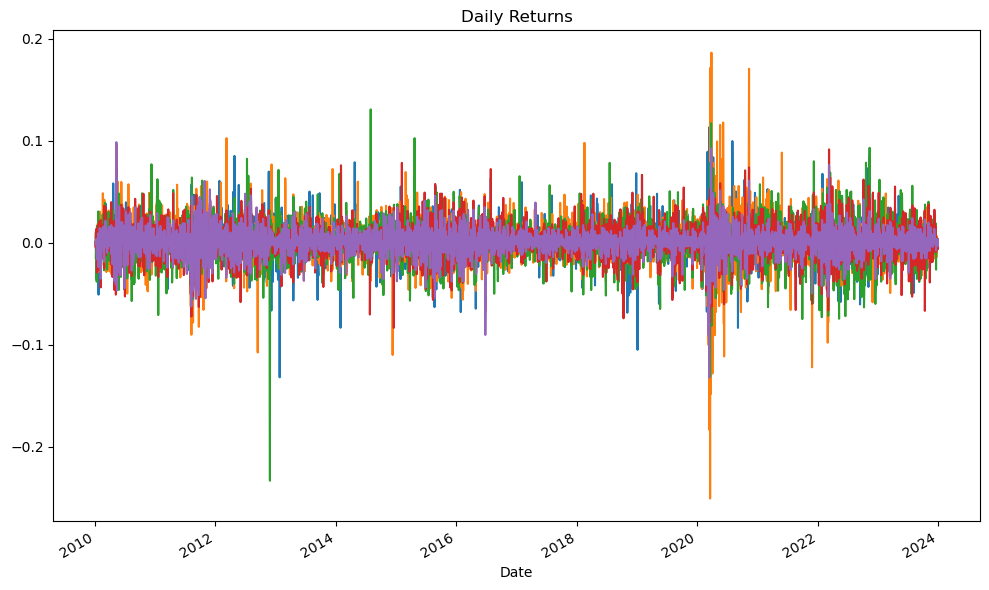

In [69]:
returns.plot(legend=0, figsize=(10,6), title='Daily Returns')
plt.tight_layout()

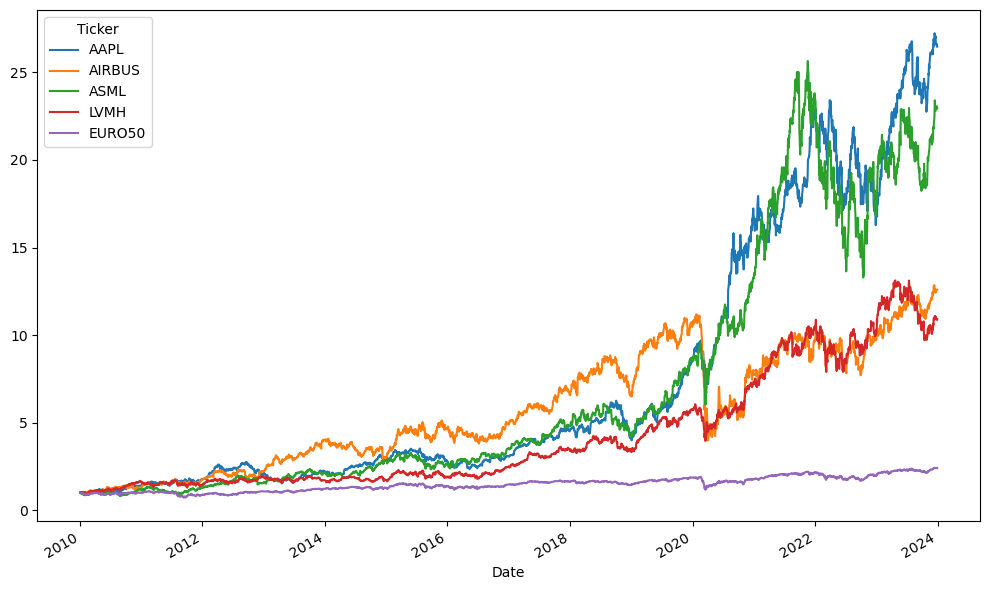

In [70]:
returns.cumsum().apply(np.exp).plot(legend=1, figsize=(10,6))
plt.tight_layout()

## Analysis of Correlation

As can be seen from the plot our portfolios are correlated and some of the assets have severe correlations. To expand on these correlations we should use copula to analyze behavior of returns better.

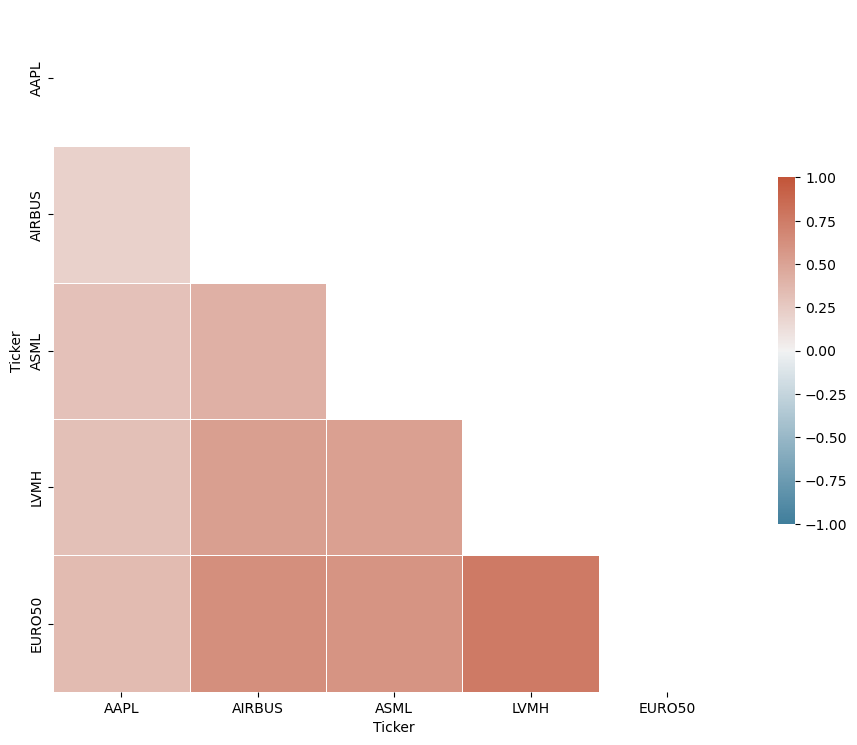

In [8]:
# calculate the correlation matrix to measure the linear relationships between the variables:
corr_matrix = returns.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # Create a mask for the upper triangle of the correlation matrix.

# Visualizing:
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(230, 20, as_cmap=True)     # Setting Colors
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

# Copulas

In [9]:
from copulas.bivariate import Gumbel, Clayton, Frank
from copulas.bivariate import Bivariate 
from scipy.stats import rankdata

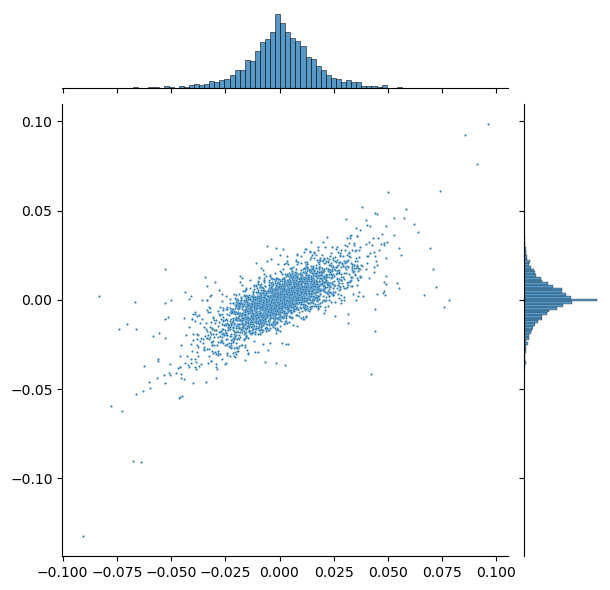

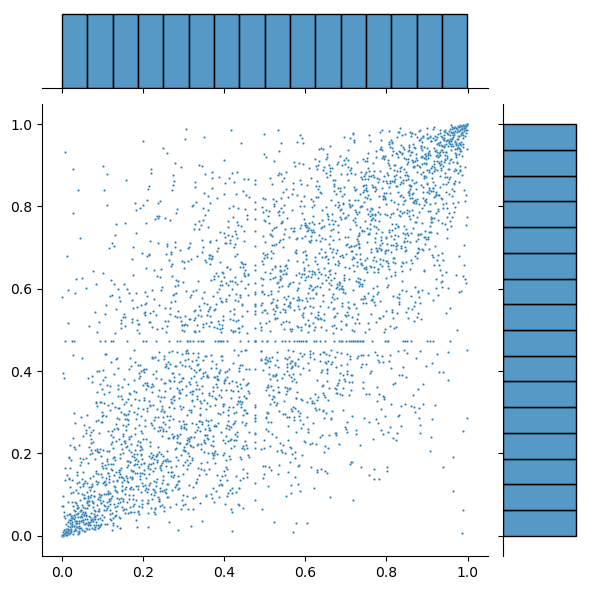

In [10]:
# Function to transform data to uniform [0, 1] using empirical CDF
def to_uniform(data):
    return (rankdata(data) - 0.5) / len(data)

# Choosing pair of data
copula_data = returns[['LVMH', 'EURO50']].to_numpy()        # We choose them because they have the highest correlation
# Transform data to uniform
uniform_data = np.column_stack((to_uniform(copula_data[:, 0]), to_uniform(copula_data[:, 1])))

sns.jointplot(x=copula_data[:, 0], y=copula_data[:, 1], kind='scatter', s=2.5)      # Joint plot of returns for our assets
sns.jointplot(x=uniform_data[:, 0], y=uniform_data[:, 1], kind='scatter', s=2.5)    # Joint plot of returns for our assets converted to uniform

In [11]:
# Finding the Optimal Copula according to the Algorithm:
# https://github.com/sdv-dev/Copulas/blob/main/copulas/bivariate/base.py
bivariate_copula = Bivariate()
best_fit_copula = bivariate_copula.select_copula(uniform_data)
print("The most suitable copula is: ", best_fit_copula.copula_type, ", tau= ", best_fit_copula.tau, " theta= ", best_fit_copula.theta)

The most suitable copula is:  CopulaTypes.GUMBEL , tau=  0.5495336776259725  theta=  2.219921779567992


## Bivariate - Archimedean

### Clayton

In [12]:
# Fit a Gumbel copula
clayton_copula = Clayton()
clayton_copula.fit(uniform_data)

# Display the parameter, in case of Gumbel it's mainly the 'theta'
print(f"Fitted Theta: {clayton_copula.theta}")
print(f"Fitted Tau: {clayton_copula.tau}")
print(f"Log Prob per Point: {clayton_copula.log_probability_density(uniform_data)}")

Fitted Theta: 2.4398435591359844
Fitted Tau: 0.5495336776259725
Log Prob per Point: [ 0.51494434  0.67994576 -0.18261824 ...  0.51494434  0.81310496
  0.43961204]


c:\Users\PAOvi\anaconda3\Lib\site-packages\seaborn\distributions.py:1185: UserWarning: The following kwargs were not used by contour: 's'
  cset = contour_func(


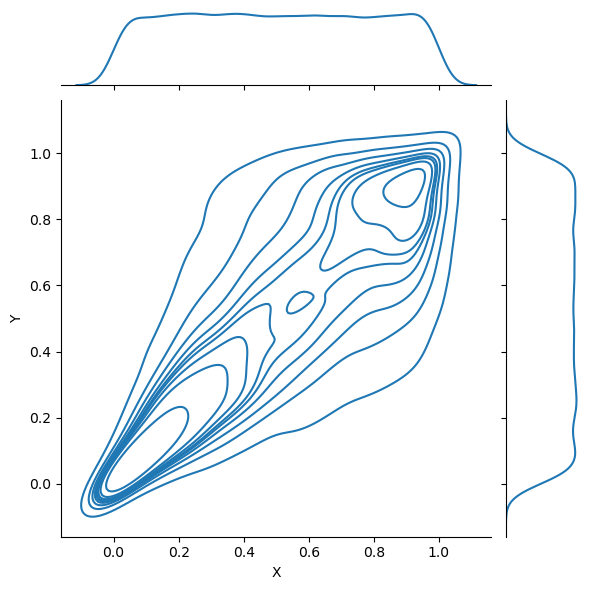

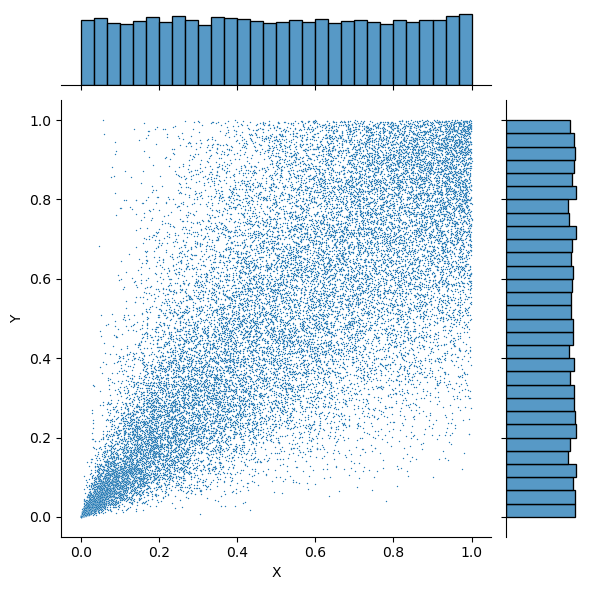

In [13]:
# Generate synthetic data
synthetic_data = clayton_copula.sample(25_000)
synthetic_data = pd.DataFrame(list(map(np.ravel, synthetic_data)))
synthetic_data.columns = ['X', 'Y']

# Example of using synthetic data (plotting or further statistical analysis)
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='kde', s=1.0)
sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)
plt.show()


### Frank

In [14]:
# Fit a Gumbel copula
frank_copula = Frank()
frank_copula.fit(uniform_data)

# Display the parameter, in case of Gumbel it's mainly the 'theta'
print(f"Fitted Theta: {frank_copula.theta}")
print(f"Fitted Tau: {frank_copula.tau}")
print(f"Log Prob per Point: {frank_copula.log_probability_density(uniform_data)}")

Fitted Theta: 6.717700941153725
Fitted Tau: 0.5495336776259725
Log Prob per Point: [ 0.58907066  0.60583324 -0.48596058 ...  0.58907066  0.65717553
  0.58760663]


c:\Users\PAOvi\anaconda3\Lib\site-packages\seaborn\distributions.py:1185: UserWarning: The following kwargs were not used by contour: 's'
  cset = contour_func(


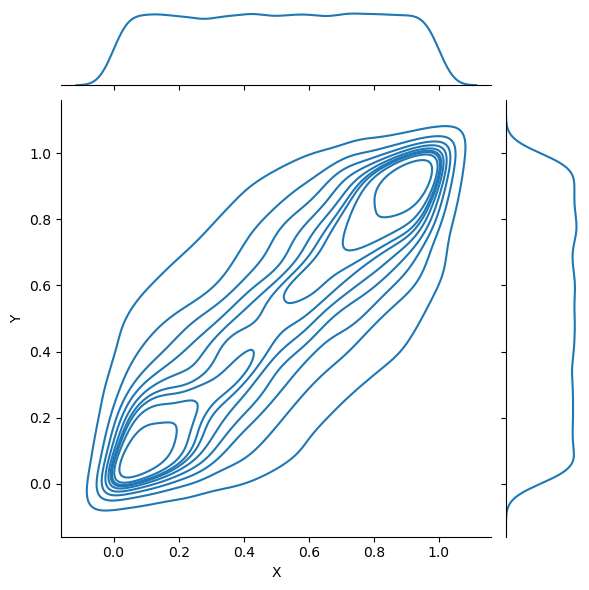

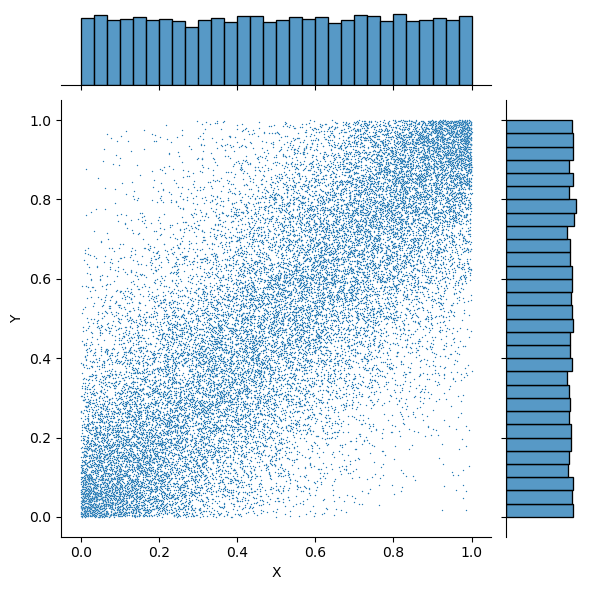

In [15]:
# Generate synthetic data
synthetic_data = frank_copula.sample(25_000)
synthetic_data = pd.DataFrame(list(map(np.ravel, synthetic_data)))
synthetic_data.columns = ['X', 'Y']

# Example of using synthetic data (plotting or further statistical analysis)
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='kde', s=1.0)
sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)
plt.show()


### Gumbel

In [16]:
# Fit a Gumbel copula
gumbel_copula = Gumbel()
gumbel_copula.fit(uniform_data)

# Display the parameter, in case of Gumbel it's mainly the 'theta'
print(f"Fitted Theta: {gumbel_copula.theta}")
print(f"Fitted Tau: {gumbel_copula.tau}")
print(f"Log Prob per Point: {gumbel_copula.log_probability_density(uniform_data)}")

Fitted Theta: 2.219921779567992
Fitted Tau: 0.5495336776259725
Log Prob per Point: [ 0.49762634  0.50516613 -0.33582377 ...  0.49762634  0.54867919
  0.56783758]


c:\Users\PAOvi\anaconda3\Lib\site-packages\seaborn\distributions.py:1185: UserWarning: The following kwargs were not used by contour: 's'
  cset = contour_func(


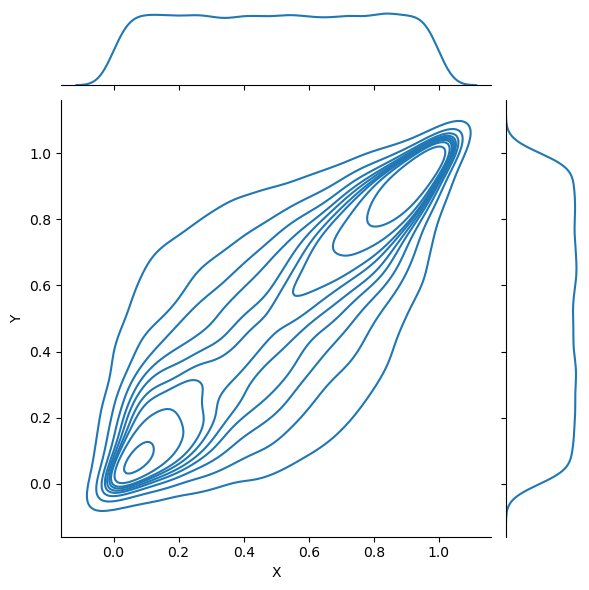

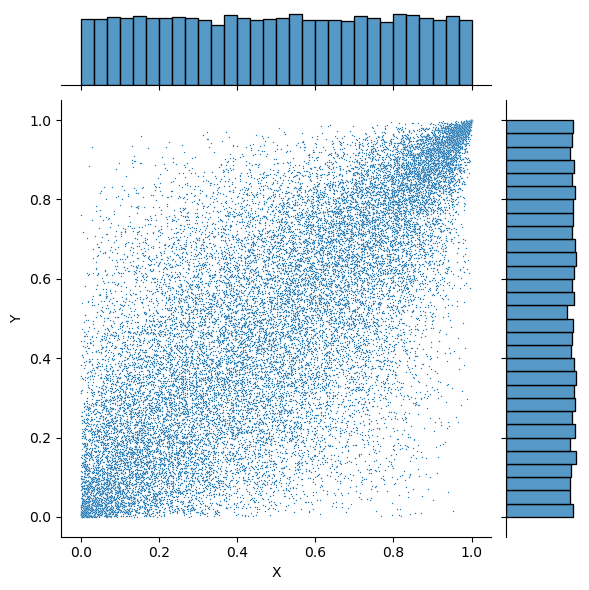

In [17]:
# Generate synthetic data
synthetic_data = gumbel_copula.sample(25_000)
synthetic_data = pd.DataFrame(list(map(np.ravel, synthetic_data)))
synthetic_data.columns = ['X', 'Y']

# Example of using synthetic data (plotting or further statistical analysis)
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='kde', s=1.0)
sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)
plt.show()


### Gaussian

To model simpler distributions, we define them as univariate and combine under joint copula. This is the way it is modeled in the paclage through wrapers.

In [18]:
from copulas.multivariate import GaussianMultivariate, Multivariate
from copulas.univariate import GaussianUnivariate, StudentTUnivariate, GammaUnivariate

copula_data_df = returns[['LVMH', 'EURO50']]        # This type of copula takes dataframe as input

In [19]:
gaussian_copula = GaussianMultivariate(distribution={
    "LVMH": GaussianUnivariate,
    "EURO50": GaussianUnivariate
})
gaussian_copula.fit(copula_data_df)            # Here we fit raw data, as it transforms them into the uniform automatically

normal_parameters = gaussian_copula.to_dict()

print("\nCorrelations between variables: \n", normal_parameters['correlation'])
print("Optimal fitted Gaussian distributions for each parameter: \n", normal_parameters['univariates'])


Correlations between variables: 
 [[1.0, 0.7591771536247173], [0.7591771536247173, 1.0]]
Optimal fitted Gaussian distributions for each parameter: 
 [{'loc': 0.000660434540714432, 'scale': 0.01688757819183749, 'type': 'copulas.univariate.gaussian.GaussianUnivariate'}, {'loc': 0.0002427837903614415, 'scale': 0.01265365591356408, 'type': 'copulas.univariate.gaussian.GaussianUnivariate'}]


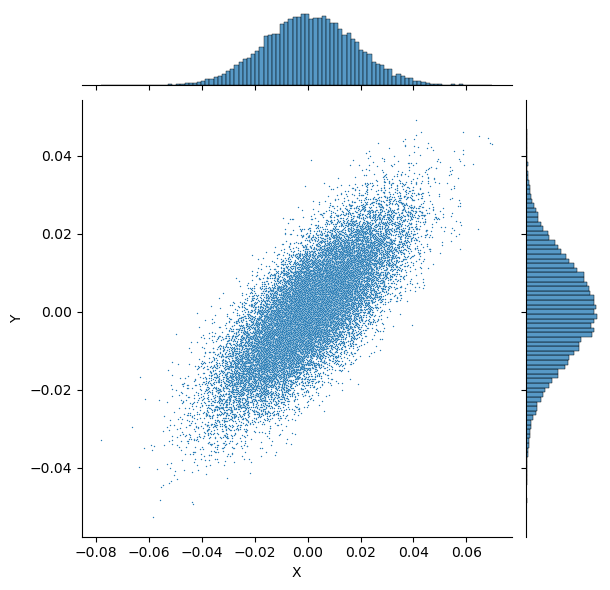

In [20]:
# Generate synthetic data
synthetic_data = gaussian_copula.sample(25_000)
synthetic_data.columns = ['X', 'Y']

# Example of using synthetic data (plotting or further statistical analysis)
sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)
plt.show()


In [21]:
# TODO: DECLARING COPULAS FROM OUR PARAMETERS

# # We can also override parameters
# new_copulas_list = [{'loc': 0.0006604346701576585, 'scale': 0.016887573938796495, 'type': 'copulas.univariate.gaussian.GaussianUnivariate'},
#                 {'loc': 0.0002427837903614415, 'scale': 0.01265365591356408, 'type': 'copulas.univariate.gaussian.GaussianUnivariate'}]

# # Update the 'loc' i.e. mean of the distribution key in the first distribution of copula
# new_copulas_list[0]['loc'] = 0.1

# # Output the updated dictionary to verify the change
# print(new_copulas_list)

# new_dist = Multivariate.from_dict(new_copulas_list)

In [22]:
# # Generate synthetic data
# synthetic_data = new_dist.sample(25_000)
# synthetic_data.columns = ['X', 'Y']

# # Example of using synthetic data (plotting or further statistical analysis)
# sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)
# plt.show()

### t-Student

In [23]:
t_Student_copula = GaussianMultivariate(distribution={
    "LVMH": StudentTUnivariate,
    "EURO50": StudentTUnivariate
})
t_Student_copula.fit(copula_data_df)            # Here we fit raw data, as it transforms them into the uniform automatically

student_parameters = t_Student_copula.to_dict()

print("\nCorrelations between variables: \n", student_parameters['correlation'])
print("Optimal fitted t-Student distributions for each parameter: \n", student_parameters['univariates'])



Correlations between variables: 
 [[1.0, 0.7552468628172686], [0.7552468628172686, 1.0]]
Optimal fitted t-Student distributions for each parameter: 
 [{'df': 3.9022131886184654, 'loc': 0.0007533138550991204, 'scale': 0.012218191711223153, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}, {'df': 2.9836721516214153, 'loc': 0.0005892807888809757, 'scale': 0.007968953188679302, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}]


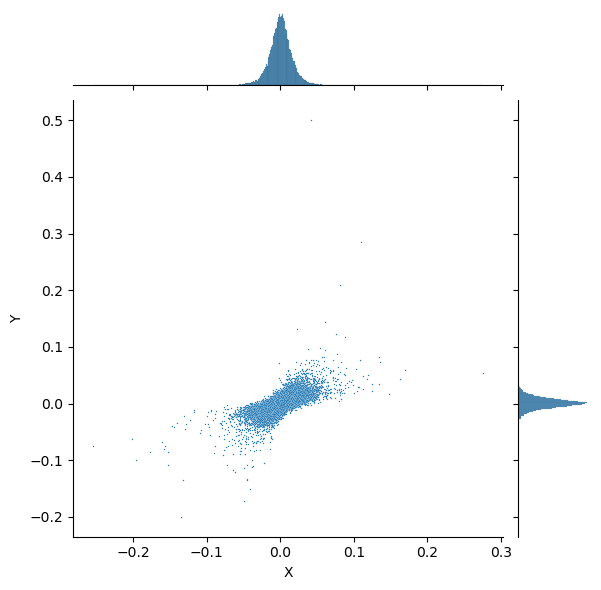

In [24]:
# Generate synthetic data
synthetic_data = t_Student_copula.sample(25_000)
synthetic_data.columns = ['X', 'Y']

# Example of using synthetic data (plotting or further statistical analysis)
sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)
plt.show()

In [25]:
# # We can also override parameters
# new_copulas_list =  [{'df': 3.90220397241767, 'loc': 0.0007533882029669375, 'scale': 0.012218171367175524, 'type': 'copulas.univariate.student_t.StudentTUnivariate'},
#                  {'df': 2.9836721516214153, 'loc': 0.0005892807888809757, 'scale': 0.007968953188679302, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}]

# # Update the 'df' i.e. degrees of freedom of the distribution key in the first distribution of copula
# new_copulas_list[0]['df'] = 8

# # Output the updated dictionary to verify the change
# print(new_copulas_list)

# new_dist = Multivariate.from_dict(new_copulas_list)

In [26]:
# # Generate synthetic data
# synthetic_data = new_dist.sample(25_000)
# synthetic_data.columns = ['X', 'Y']

# # Example of using synthetic data (plotting or further statistical analysis)
# sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)
# plt.show()

## Multivariate

In [27]:
multidim_t_Student_copula = GaussianMultivariate(distribution={
    "AAPL": StudentTUnivariate,
    "AIRBUS": StudentTUnivariate,
    "ASML": StudentTUnivariate,
    "LVMH": StudentTUnivariate,
    "EURO50": StudentTUnivariate
})

multidim_copula_df = returns[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']]        # This type of copula takes dataframe as input
multidim_t_Student_copula.fit(multidim_copula_df)            # Here we fit raw data, as it transforms them into the uniform automatically

student_parameters = multidim_t_Student_copula.to_dict()

print("\nCorrelations between variables: \n", student_parameters['correlation'])
print("Optimal fitted t-Student distributions for each parameter: \n", student_parameters['univariates'])

# Generate synthetic data
synthetic_data = multidim_t_Student_copula.sample(25_000)

print(synthetic_data)       # Not sure what else can be done with the 5D data


Correlations between variables: 
 [[1.0, 0.20038039558315981, 0.32242711530066, 0.3016710471935885, 0.32493043143144057], [0.20038039558315981, 1.0, 0.4264555497428388, 0.5283644665746767, 0.6294951663917586], [0.32242711530066, 0.4264555497428388, 1.0, 0.5363882542725027, 0.6237071642557781], [0.3016710471935885, 0.5283644665746767, 0.5363882542725027, 1.0, 0.7552468628172686], [0.32493043143144057, 0.6294951663917586, 0.6237071642557781, 0.7552468628172686, 1.0]]
Optimal fitted t-Student distributions for each parameter: 
 [{'df': 3.1236418618801176, 'loc': 0.0010851783713737464, 'scale': 0.011204369510174002, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}, {'df': 3.2162612675389086, 'loc': 0.0006323093546036936, 'scale': 0.013491814773996597, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}, {'df': 4.10864752550257, 'loc': 0.001058012239881154, 'scale': 0.014181352662574816, 'type': 'copulas.univariate.student_t.StudentTUnivariate'}, {'df': 3.9022131886184654,

# Factor Analysis

## Extending portfolio

In [28]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'NVO', 'V', 'ENGIY', 'CL=F', 'GC=F']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  10 of 10 completed


In [29]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'NVO': 'NOVO', 'V': 'VISA', 'ENGIY': 'ENGIE', 'CL=F': 'OIL', 'GC=F': 'GOLD'})
# Getting Daily Log Returns
returns = data.apply(np.log).diff(1)
# Filling non-trading days with zero returns
returns = returns.fillna(0)

In [30]:
returns

Ticker,AAPL,AIRBUS,ASML,OIL,ENGIE,GOLD,LVMH,NOVO,EURO50,VISA
Date,,,,,,,,,,
2010-01-04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-05,0.001728,-0.003222,0.001853,0.003185,0.000000,0.000358,-0.004712,-0.014734,-0.001808,-0.011525
2010-01-06,-0.016034,0.008924,0.010641,0.017097,0.001143,0.015795,0.009655,0.011682,-0.000903,-0.013519
2010-01-07,-0.001850,0.009901,-0.018489,-0.006271,-0.013809,-0.002468,0.011316,-0.008594,-0.000780,0.009264
2010-01-08,0.006627,0.009804,-0.034166,0.001088,0.017232,0.004491,0.013411,0.011798,0.003482,0.002763
...,...,...,...,...,...,...,...,...,...,...
2023-12-22,-0.005563,0.006620,0.001464,-0.004476,-0.008401,0.008789,-0.007697,-0.007469,-0.001098,-0.004286
2023-12-26,-0.002845,0.000000,0.000000,0.026958,0.008959,0.000535,0.000000,-0.000292,0.000000,0.002821
2023-12-27,0.000518,0.000000,0.000000,-0.019509,-0.001674,0.011449,0.000000,0.009692,0.000000,-0.000888


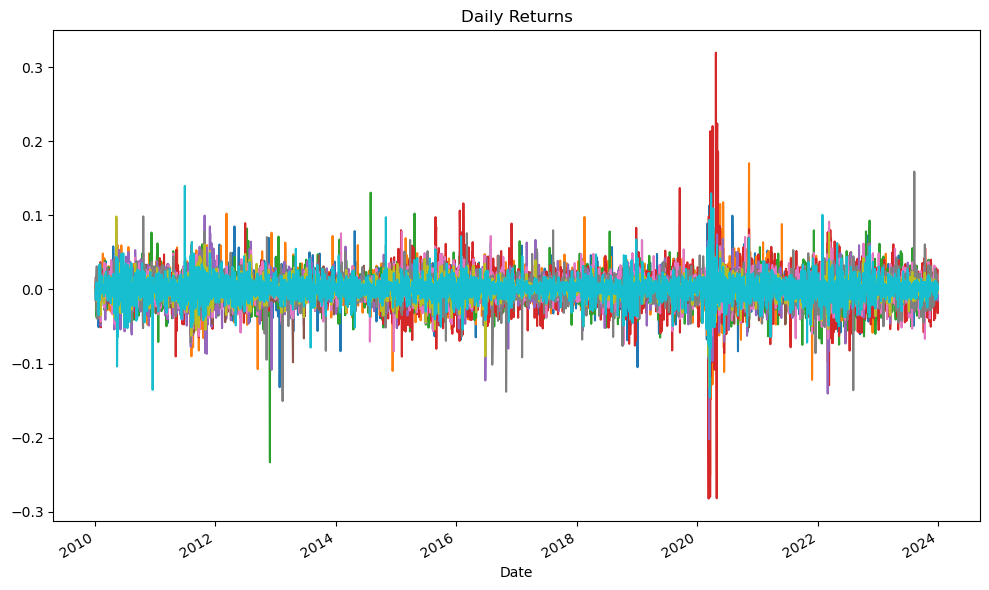

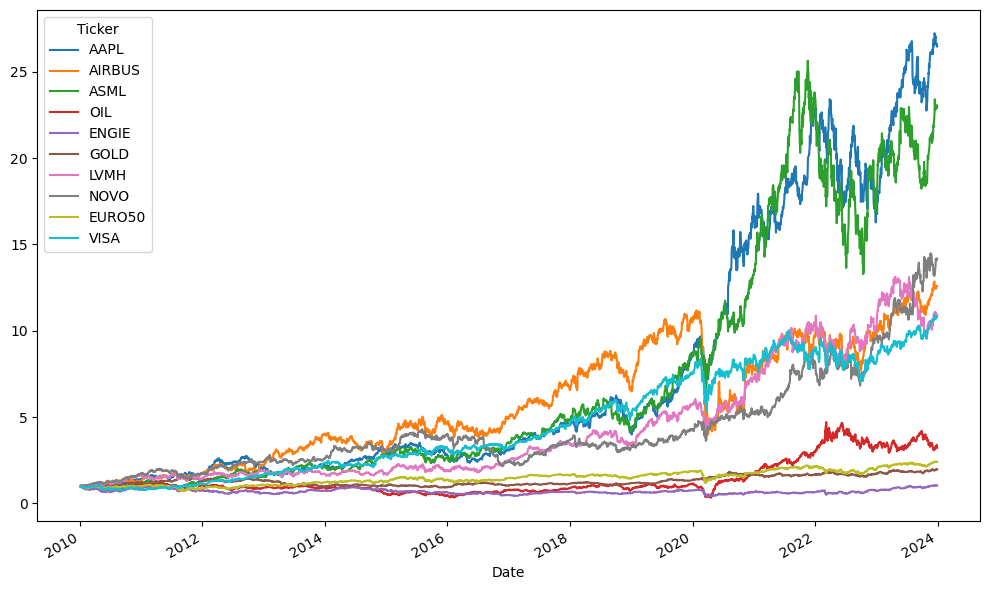

In [31]:
returns.plot(legend=0, figsize=(10,6), title='Daily Returns')
plt.tight_layout()

returns.cumsum().apply(np.exp).plot(legend=1, figsize=(10,6))
plt.tight_layout()

# calculate the correlation matrix to measure the linear relationships between the variables:
corr_matrix = returns.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # Create a mask for the upper triangle of the correlation matrix.

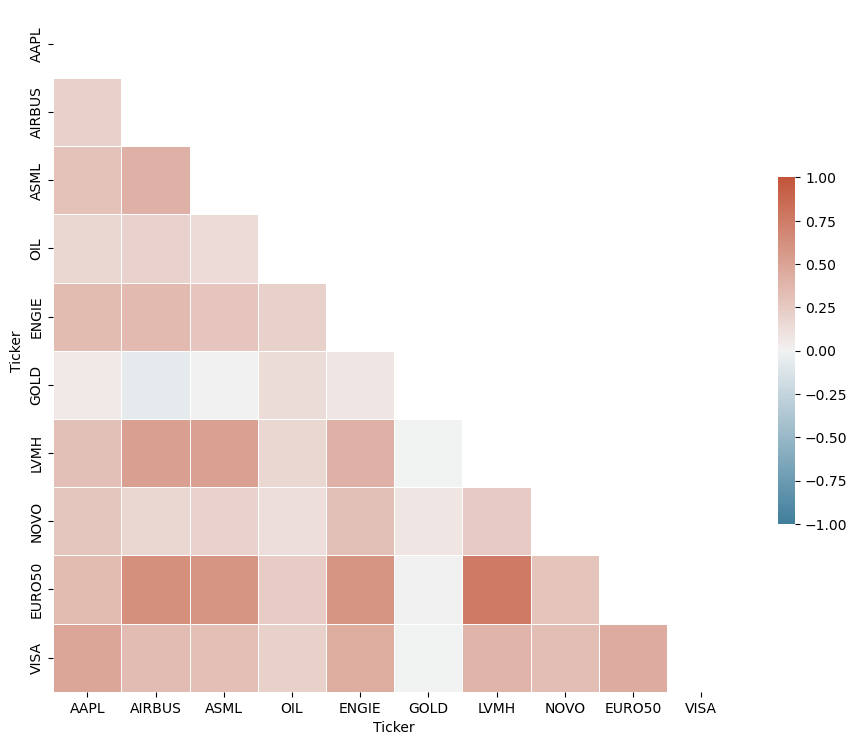

In [32]:
# Visualizing:
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(230, 20, as_cmap=True)     # Setting Colors
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

## PCA

In [79]:
n = 5
pca = skd.PCA(n_components=n)
df_pca = pca.fit_transform(returns)

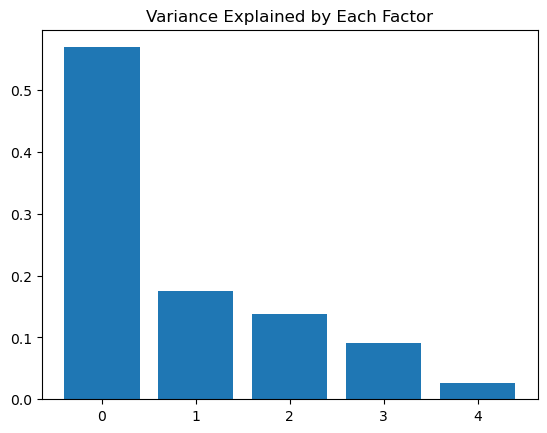

In [80]:
plt.bar(range(0, len(pca.explained_variance_)), pca.explained_variance_ratio_)
plt.title("Variance Explained by Each Factor")
plt.show()

In [35]:
loadings = pca.components_.T
loadings_column = [f'PC{i}' for i in range(n)]
df_loadings = pd.DataFrame(loadings, columns=loadings_column, index=returns.columns)

[Text(0, 0.5, 'PC0'),
 Text(0, 1.5, 'PC1'),
 Text(0, 2.5, 'PC2'),
 Text(0, 3.5, 'PC3'),
 Text(0, 4.5, 'PC4')]

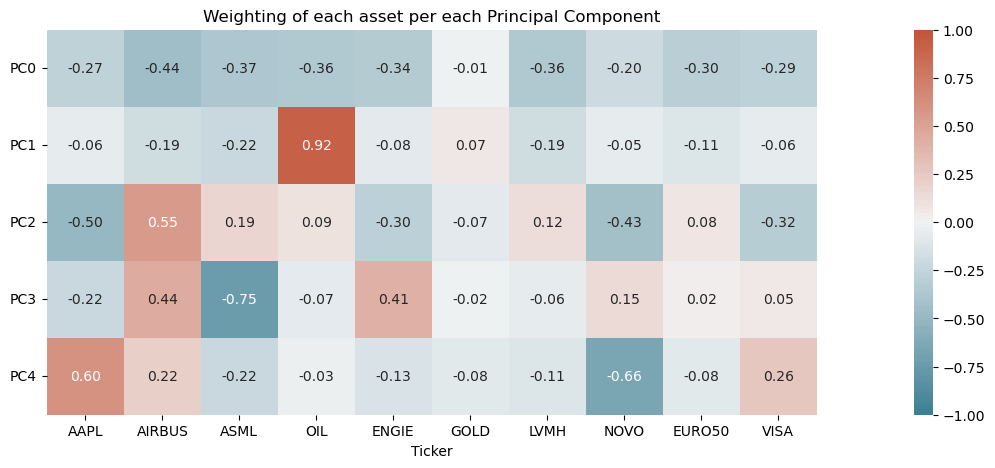

In [36]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Principle Component with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)

# Seems like
# PC0 - is general shock in economy
# PC1 - Oil's influence
# PC2 - EU specific shocks
# PC3 - Something tech specific
# PC4 - Something also sector specific

## Factor Analysis

In [41]:
fa = FactorAnalyzer(n, rotation=None)
fa.fit(returns)

FactorAnalyzer(n_factors=5, rotation=None, rotation_kwargs={})

In [42]:
fa_loadings = fa.loadings_
fa_loadings_column = [f'FA{i}' for i in range(1, n + 1)]
df_loadings_fa = pd.DataFrame(fa_loadings, columns=fa_loadings_column, index=returns.columns)

[Text(0, 0.5, 'FA1'),
 Text(0, 1.5, 'FA2'),
 Text(0, 2.5, 'FA3'),
 Text(0, 3.5, 'FA4'),
 Text(0, 4.5, 'FA5')]

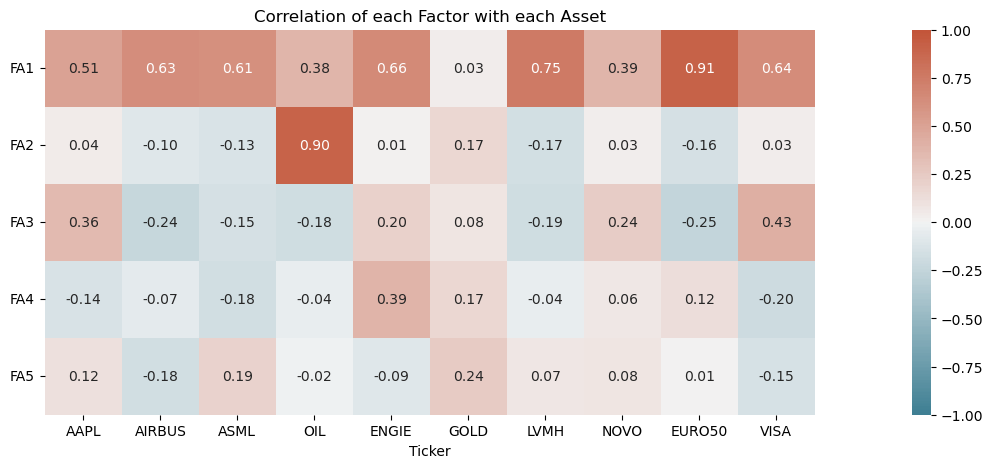

In [43]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Factor with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings_fa.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)

<Axes: title={'center': 'FA5'}, xlabel='Ticker'>

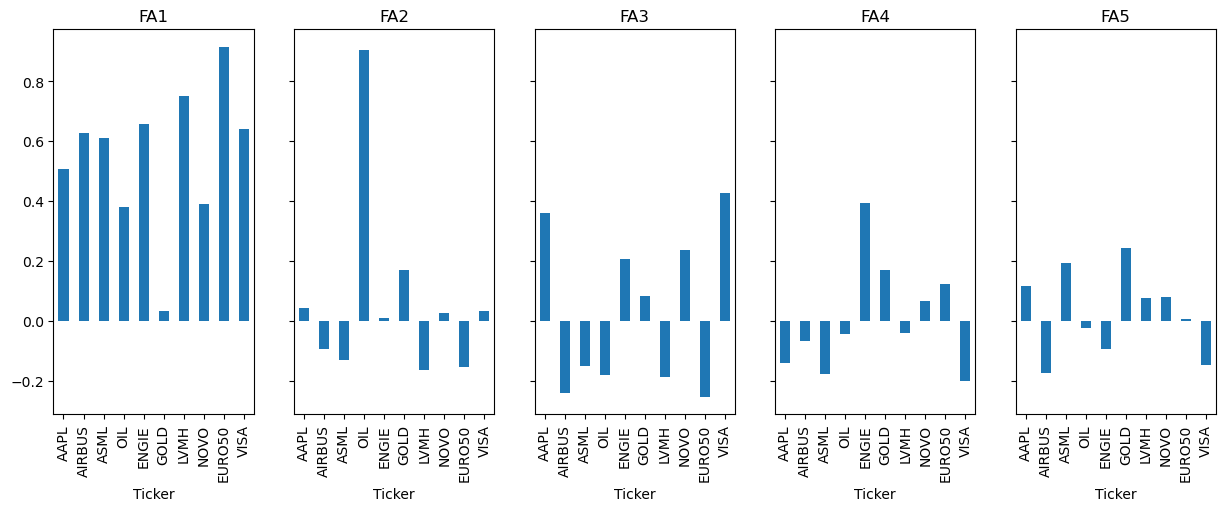

In [47]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, sharey=True)
fig.set_figheight(5)
fig.set_figwidth(15)
df_loadings_fa['FA1'].plot.bar(title='FA1', ax=ax1)
df_loadings_fa['FA2'].plot.bar(title='FA2', ax=ax2)
df_loadings_fa['FA3'].plot.bar(title='FA3', ax=ax3)
df_loadings_fa['FA4'].plot.bar(title='FA4', ax=ax4)
df_loadings_fa['FA5'].plot.bar(title='FA5', ax=ax5)

## Adding Orthogonal Rotation

In [48]:
fa = FactorAnalyzer(n, rotation='varimax')
fa.fit(returns)

FactorAnalyzer(n_factors=5, rotation='varimax', rotation_kwargs={})

In [49]:
fa_loadings = fa.loadings_
fa_loadings_column = [f'FA{i}' for i in range(1, n + 1)]
df_loadings_fa = pd.DataFrame(fa_loadings, columns=fa_loadings_column, index=returns.columns)

[Text(0, 0.5, 'FA1'),
 Text(0, 1.5, 'FA2'),
 Text(0, 2.5, 'FA3'),
 Text(0, 3.5, 'FA4'),
 Text(0, 4.5, 'FA5')]

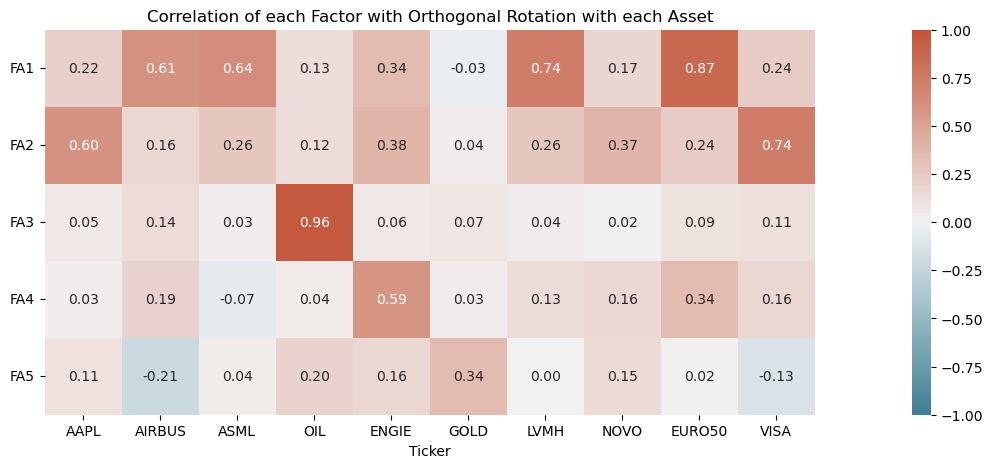

In [50]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Factor with Orthogonal Rotation with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings_fa.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)

<Axes: title={'center': 'FA5'}, xlabel='Ticker'>

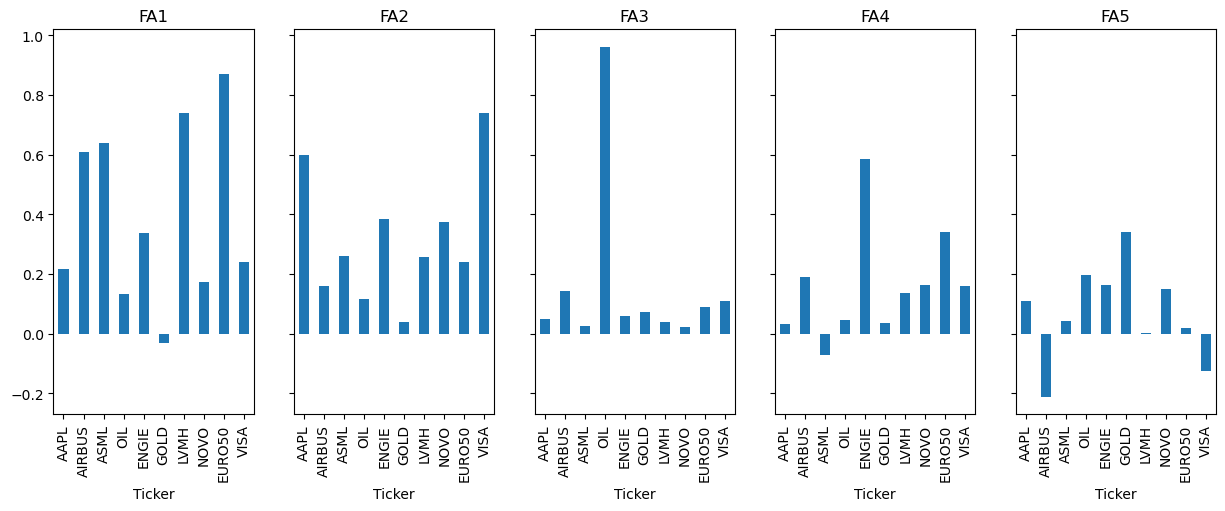

In [52]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, sharey=True)
fig.set_figheight(5)
fig.set_figwidth(15)
df_loadings_fa['FA1'].plot.bar(title='FA1', ax=ax1)
df_loadings_fa['FA2'].plot.bar(title='FA2', ax=ax2)
df_loadings_fa['FA3'].plot.bar(title='FA3', ax=ax3)
df_loadings_fa['FA4'].plot.bar(title='FA4', ax=ax4)
df_loadings_fa['FA5'].plot.bar(title='FA5', ax=ax5)

## Adding Oblique Rotation

In [53]:
fa = FactorAnalyzer(n, rotation='oblimin')
fa.fit(returns)

FactorAnalyzer(n_factors=5, rotation='oblimin', rotation_kwargs={})

In [54]:
fa_loadings = fa.loadings_
fa_loadings_column = [f'FA{i}' for i in range(1, n + 1)]
df_loadings_fa = pd.DataFrame(fa_loadings, columns=fa_loadings_column, index=returns.columns)

[Text(0, 0.5, 'FA1'),
 Text(0, 1.5, 'FA2'),
 Text(0, 2.5, 'FA3'),
 Text(0, 3.5, 'FA4'),
 Text(0, 4.5, 'FA5')]

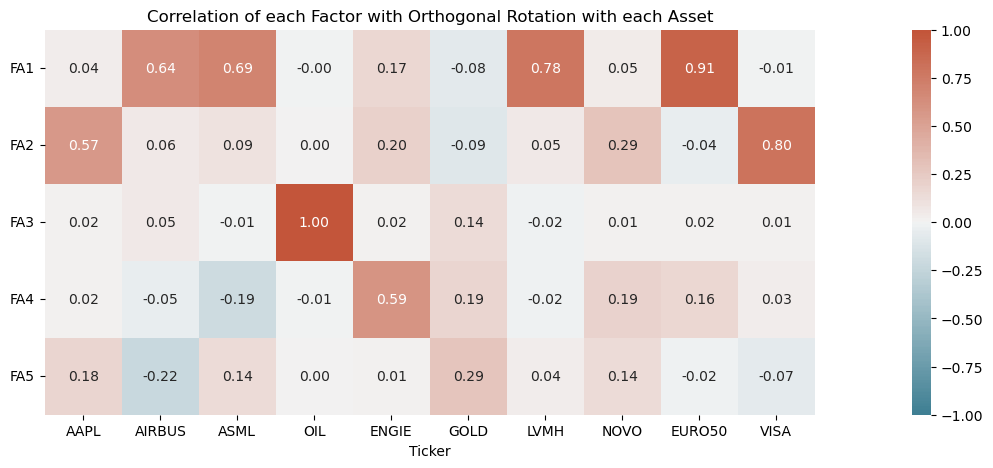

In [55]:
plt.figure(figsize=(25,5))
plt.title("Correlation of each Factor with Orthogonal Rotation with each Asset")

# plot the heatmap for correlation matrix
ax = sns.heatmap(df_loadings_fa.T, 
                 vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(220, 20, n=200),
                 square=True, annot=True, fmt='.2f')

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0)

<Axes: title={'center': 'FA5'}, xlabel='Ticker'>

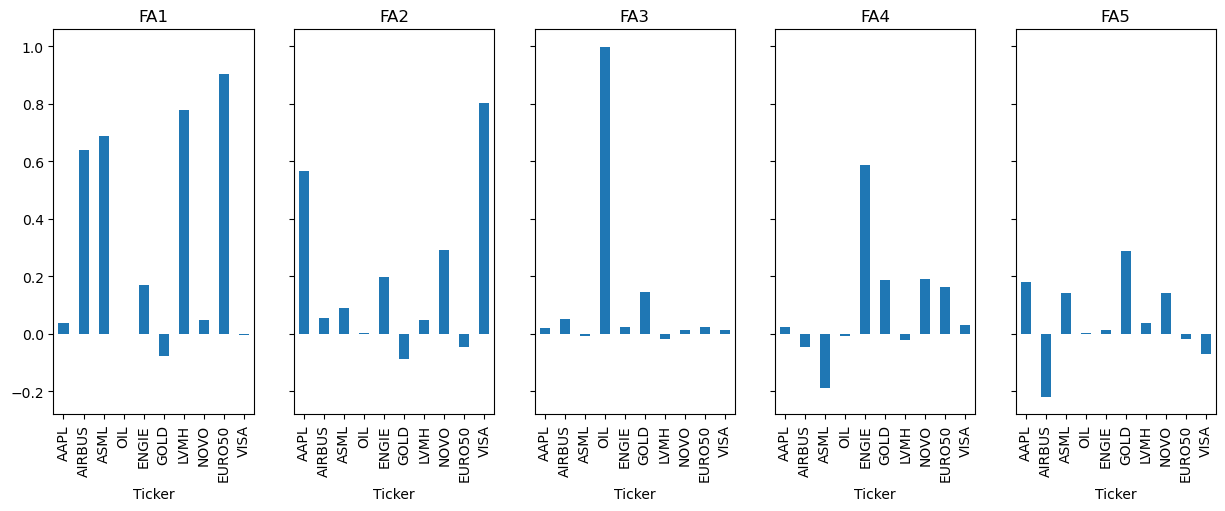

In [57]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, sharey=True)
fig.set_figheight(5)
fig.set_figwidth(15)
df_loadings_fa['FA1'].plot.bar(title='FA1', ax=ax1)
df_loadings_fa['FA2'].plot.bar(title='FA2', ax=ax2)
df_loadings_fa['FA3'].plot.bar(title='FA3', ax=ax3)
df_loadings_fa['FA4'].plot.bar(title='FA4', ax=ax4)
df_loadings_fa['FA5'].plot.bar(title='FA5', ax=ax5)